# Numerical Exercises 1

## Exercise 1.1
### **The problem: Pseudo-Random Number generator test**

1. $\langle r \rangle = \int_0^1 r dr = 1/2$. Make a picture of the estimation of $\langle r \rangle$ and its uncertainty (which corresponds to Standard Deviation of the mean for the estimation of $\langle r \rangle$) with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties).

2. $\sigma^2 = \int_0^1 (r-1/2)^2 dr = 1/12$. Make a picture of the estimation of $\sigma^2$ and its uncertainty (which corresponds to Standard Deviation of the mean for the estimation of $\langle (r-1/2)^2 \rangle$) with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties).

3. Divide $[0,1]$ into $M$ identical sub-intervals and implement the $\chi^2$ test. Obviously, the number of expected events observed in each sub-interval after $n$ *throws*, according to a uniform distribution, is $np = n\times 1/M= n/M$. Fix $M=10^2$ and use for $n$ the first $10^4$ pseudo-random numbers, then the successive $10^4$ pseudo-random numbers, and so on ... 100 times. Plot $\chi^2_j$ for $j=1, ..., 100$. In this case the chi-square statistic is:
$$\chi^2 = \sum_{i=1}^M \frac{\left( n_i - n/M \right)^2}{n/M}$$


### Data blocking method 
A fundamental step in every Monte Carlo calculation is the estimation of its statistical uncertainty, it's a must! Your task would not be completed if you had not calculated it.

In computing the statistical uncertainties, i.e. the standard deviation of the mean, you need an estimation of the variance $\sigma^2$, the second central moment. First of all note that the variance can be computed from
$$\sigma^2_A := \langle (A-\langle A\rangle)^2\rangle = \langle A^2 \rangle -\langle A\rangle^2 $$
What is the best way to estimate $\sigma^2_A$? Imagine that your Monte Carlo estimation of $A$ is obtained from a calculation which uses $M$ Monte Carlo "steps" (intentionally, here I am generic because what is a single "step" in a Monte Carlo calculation strictly depends on the specific calculation); you can always divide such $M$ Monte Carlo "steps" in $N$ blocks, with $N<M$. In each block, you can use your $M/N$ Monte Carlo "steps" to obtain an estimate of $A$, let me call it $A_i$ with $i=1,N$, and then you have also $A^2_i$ with $i=1,N$.
At this point everything becomes clear:
$$ \langle A^2 \rangle \simeq \frac{1}{N} \sum_{i=1}^N A^2_i \quad \quad \langle A\rangle^2 \simeq \left( \frac{1}{N} \sum_{i=1}^N A_i \right)^2 $$
and finally the statistical uncertainty with $N$ :
$$\frac{\sigma}{\sqrt{N-1}} \simeq \sqrt{\frac{1}{N-1} \left[ \frac{1}{N} \sum_{i=1}^N A^2_i - \left( \frac{1}{N} \sum_{i=1}^N A_i \right)^2 \right]} $$

### **Solution**

### 0. Code 
Before I begin with the solution, I’ll briefly discuss the structure I’ve chosen for my code to implement the blocking method. I’ve created a `DataBlocking` class, which, in addition to storing the mean value of the quantity under investigation, allows for the calculation of its cumulative mean value and error. The class has the following internal variables:
* $M$ : number of total throws
* $N$ : number of blocks 
* $L = M/N$ : number of throws per block 

The class implements a **virtual method** (`simulate_block()`), which finds the mean value of L throws. This method has to be implemented in each **child class** of the excercises that uses the data blocking method. 

Furthermore, the method `run_DB()` completes the rest of the job, calling `simulate_block()` and evaluating means and statistical uncertanties. This approach has been succesful because in the next exercises i just had to implement `simulate_block()` and few other adjustments.

Below is the method `run_DB()` using the aforementioned variables:
```c++
void run_DB() {                            // Core method executing the Data Blocking method
               fill(sum_prog.begin(), sum_prog.end(), 0.0);
               vector<double> av2(N,0.0);            // Vector storing the square of the average of each single block
               vector<double> su2_prog(N, 0.0);      // Vector storing the progressive sum of the squared averages

               double accum_sum = 0.0;
               double accum_su2 = 0.0;

               for (int i = 0; i < N; i++) {
                    ave[i] = simulate_block();
                    av2[i] = ave[i] * ave[i];

                    accum_sum += ave[i];
                    accum_su2 += av2[i];

                    sum_prog[i] = accum_sum / (i + 1);
                    su2_prog[i] = accum_su2 / (i + 1);
                    
                    err_prog[i] = error(sum_prog, su2_prog, i); 
               }
          }
```


### 1. Mean

The first assingment is to evaluate the mean of $M$ numbers, by perfomring the integral $\langle r \rangle = \int_{0}^{1} r dr = 1/2 $. <br> The Pseudo-Random Number generator with the method `Rannyu()` gives a number in range $[0,1)$. It's a deterministic algorithm, so the goal is to use Data Blocking method to avoid autocorrelation between draws, dividing $M$ throws into $N$ subgroups, as explained in *Code* section. <br>
So, as said before, i had to implement a child class `UniformMean` that includes the method `simulate_block()`, that in this case performs the mean over $N$ elements:
$$ r_b \simeq \frac{1}{L} \sum_{i = 1}^L r_i$$
where $b$ stands for *block*. <br>
In this way, $r_b$ becomes the *real* measure, and the final value is given by the average between $N$ values of $r_b$. Hence, looking at *Data blocking*, section $r_b$ is the value called $A_i$, and we can use those formulas in order to evaluate the progressive and final values of both mean and error (in my code is performed by `run_DB()`). 

Now we can look at the results.

**Plot parameters**:
* $M = 10^6$ 
* $N = 10^2$
* $L = 10^4$

In [7]:
import numpy as np
import matplotlib.pyplot as plt
throws, _, value, err = np.loadtxt("1.1/OUTPUT/unif_mean.dat", unpack=True)
throws_var, _, value_var, err_var = np.loadtxt("1.1/OUTPUT/unif_var.dat", unpack=True)
x, chi = np.loadtxt("1.1/OUTPUT/chi2_100.dat", unpack=True)
throws_buff, value_buff, err_buff = np.loadtxt("1.3/OUTPUT/buff.dat", unpack=True) 

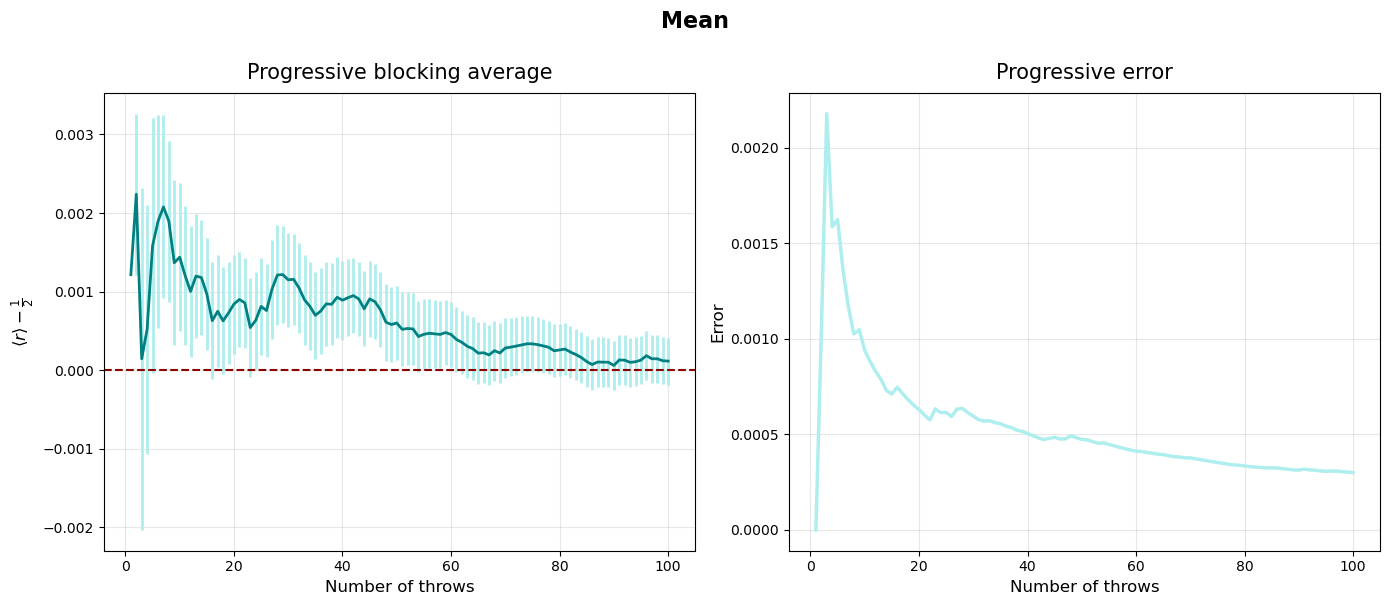

In [8]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), tight_layout=True)
fig.suptitle("Mean", fontsize=16, fontweight='bold', y=1)
axs[0].errorbar(throws, value, yerr=err, fmt='-', color='teal', ecolor='paleturquoise', elinewidth=2, linewidth=2)
axs[0].set_title('Progressive blocking average', fontsize=15, pad=10)
axs[0].set_xlabel('Number of throws',  fontsize=12)
axs[0].set_ylabel(r'$\langle r \rangle - \frac{1}{2}$', fontsize=12)
axs[0].grid(True, alpha=0.3)
axs[0].axhline(y=0, color='darkred', linestyle='--', linewidth=1.5)
#axs[0].set_xlim(0, max(throws))

axs[1].plot(throws, err, label='Integral error', color='paleturquoise',  linewidth=2.5)
axs[1].set_title('Progressive error', fontsize=15, pad=10)
axs[1].grid(True, alpha=0.3)
axs[1].set_xlabel('Number of throws',  fontsize=12)
axs[1].set_ylabel('Error',  fontsize=12);
#axs[1].set_xlim(0, max(throws))

We can see the convergence of this Monte Carlo method, as $\langle r \rangle $ is within one $\sigma$ from the expected value $1/2$.

### 2. Variance 
Variance of a random variable *r* can be calculated with the integral $ \sigma^2 = \int_{0}^{1} (r - 1/2)^2 dr$, and the expected value is $1/12$. For this task, I implemented `UniformVariance`. 

**Plot parameters**:
* $M = 10^6$ 
* $N = 10^2$
* $L = 10^4$

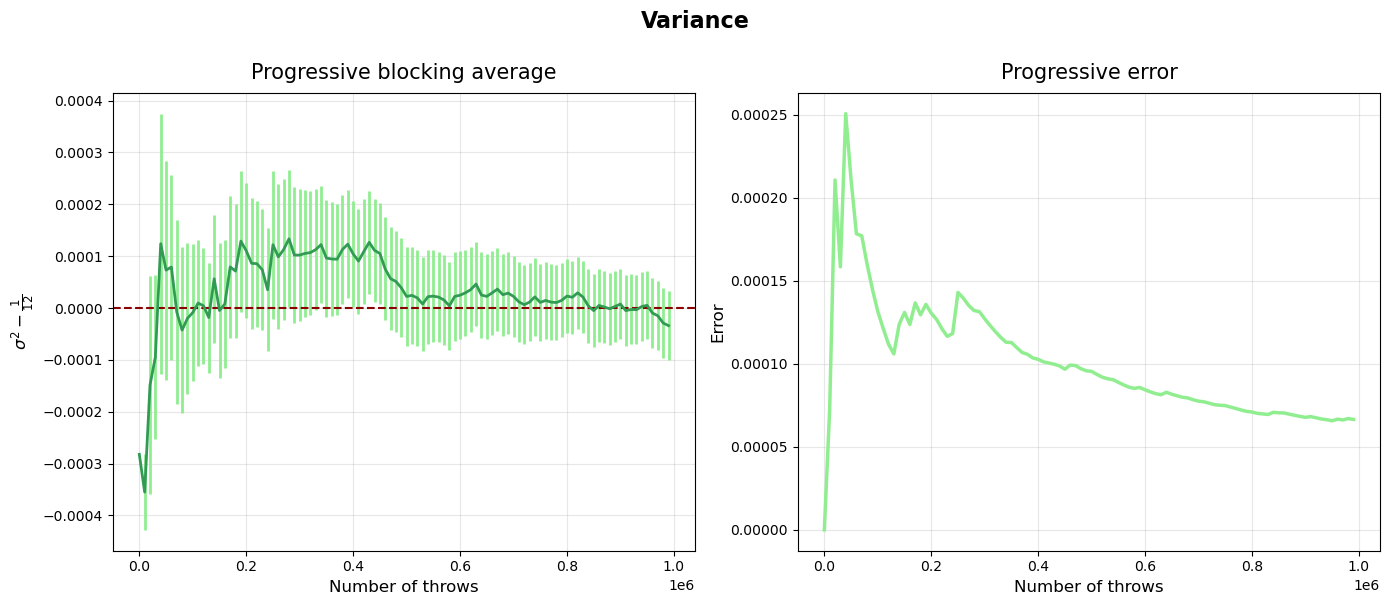

In [148]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), tight_layout=True)
fig.suptitle("Variance", fontsize=16, fontweight='bold', y=1)
axs[0].errorbar(throws_var, value_var, yerr=err_var, fmt='-', color="#319B54", ecolor='lightgreen', elinewidth=2, linewidth=2)
axs[0].set_title('Progressive blocking average', fontsize=15, pad=10)
axs[0].set_xlabel('Number of throws',  fontsize=12)
axs[0].set_ylabel(r'$\sigma^2 - \frac{1}{12}$', fontsize=12)
axs[0].grid(True, alpha=0.3)
axs[0].axhline(y=0, color='darkred', linestyle='--', linewidth=1.5)
#axs[0].set_xlim(0, max(throws))

axs[1].plot(throws, err, label='Integral error', color='lightgreen',  linewidth=2.5)
axs[1].set_title('Progressive error', fontsize=15, pad=10)
axs[1].grid(True, alpha=0.3)
axs[1].set_xlabel('Number of throws',  fontsize=12)
axs[1].set_ylabel('Error',  fontsize=12);
#axs[1].set_xlim(0, max(throws))

As we can see, the extimation of $ \langle \sigma^2 \rangle $ is consistent with the theoretical value.

### 3. $\chi^2$ Test
Pearson's cumulative test statistic $\chi^2$ is the standard measure for quantifying the discrepancy between experimental data and a theoretical model. In this case, it is used to evaluate whether our pseudo-random number generator produces values that are **uniformly distributed**. In this section, I used the parameters and formula recommended by the assignment. The expected value of $\chi^2$ should be 100, since $(n_i-n/M)^2\simeq n/M$.

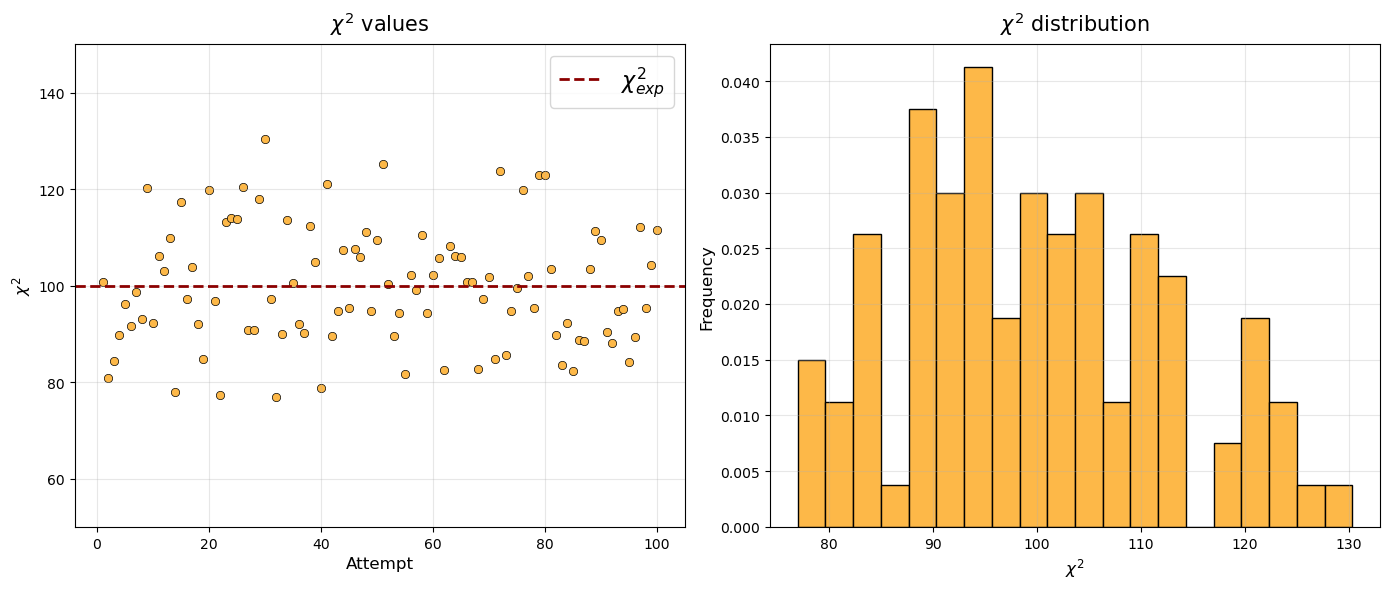

In [ ]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), tight_layout=True)
axs[0].scatter(x, chi, color="#FDB848", edgecolors='black',linewidths=0.5)
axs[0].set_title(r'$\chi^2$ values', fontsize=15, pad=10)
axs[0].set_xlabel('Attempt',  fontsize=12)
axs[0].set_ylabel(r'$\chi^2$', fontsize=12)
axs[0].grid(True, alpha=0.3)
axs[0].axhline(y=100, color='darkred', label=r'$\chi^2_{exp}$',linestyle='--', linewidth=2)
axs[0].set_ylim(50, 150)
axs[0].legend(fontsize=16)

axs[1].hist(chi, bins=20, density=True, color="#FDB848" , edgecolor='black')
axs[1].set_title(r'$\chi^2$ distribution', fontsize=15, pad=10)
axs[1].set_xlabel(r'$\chi^2$', fontsize=12)
axs[1].set_ylabel('Frequency', fontsize=12)
axs[1].grid(True, alpha=0.3)

In the left, we can see the scatter plot of $\chi^2$ values, in my code has been performed the average of theese values and the error (SEM): $$\langle \chi^2 \rangle = 99.80 \pm  1.2 $$
Hence, the result is consisent with the exptected value. 

On the other hand, in order to evaluate with a fit the data quality of the distribution, it could be helpful to increase the number of calculations $\chi^2$. <br> In the next histograms, I raised it from $N=100$ to $N=1000$:



In [103]:
from scipy.stats import chi2
x, chi = np.loadtxt("1.1/OUTPUT/chi2_10000.dat", unpack=True)

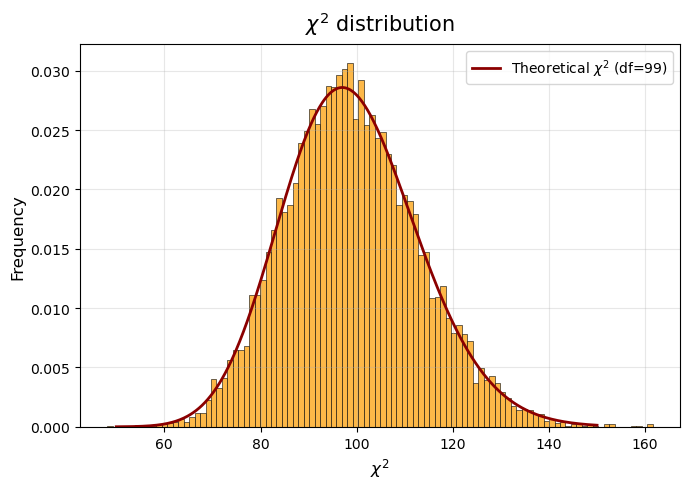

In [104]:
x_theo = np.linspace(50, 150, 500)
y_theo = chi2.pdf(x_theo, df=99)
plt.figure(figsize=(7, 5))
plt.hist(chi, bins=100, density=True, color="#FDB848" , edgecolor='black', linewidth=0.4)
plt.plot(x_theo, y_theo, color='darkred', linewidth=2, label=rf'Theoretical $\chi^2$ (df={99})')
plt.title(r'$\chi^2$ distribution', fontsize=15, pad=10)
plt.xlabel(r'$\chi^2$', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.legend()
plt.show()

The histogram seems to show good agreement with theoretical distribution oh $\chi^2$.

## Exercise 1.2
**Extend Pseudo-Random Number generator downloaded from the NSL Ariel web site and check the Central Limit Theorem:**
1. Add two probability distributions by using the method of the **inversion of the cumulative** distribution to sample from a **generic exponential distribution**, $p(x) = \lambda \exp(-\lambda x)$, $x\in [0;+\infty]$, and a **generic Cauchy-Lorentz** distribution $p(x)=\frac{1}{\pi}\frac{\Gamma}{(x-\mu)^2+\Gamma^2}$, $x\in [-\infty;+\infty]$
2. Make 3 pictures with the histograms obtained filling them with $10^4$ realizations $S_N = \frac{1}{N}\sum_{i=1}^N x_i$ (for $N=1, 2, 10, 100$), being $x_i$ a random variable sampled throwing a *standard* dice (fig.1), an *exponential* dice (fig.2, use $\lambda=1$) and a *Lorentzian* dice (fig.3, use $\mu=0$ and $\Gamma=1$).

### **Solution**
### 1. Method of the inversion of the cumulative distribution
The method of the inversion of the cumulative distribution is a widely used technique to sample random variables from a generic probability density function $p(x)$ whose cumulative distribution function is invertible. <br>
Given $p(x)$, the corresponding cumulative distribution function is: $$ F(x) = \int_{-\infty}^{x} p(t)dt $$
$F(x)$ is a monotonically non-decreasing function limited in the range $[0,1)$. Hence, we can consider $y=F(x)$ as a varibale drawn from a uniform distribution in $[0,1)$. Assuming $F(x)$ to be invertible, the desired sample $x$ distributed according $p(x)$ is obtained as follows: $$ x=F^{-1}(y)$$
The core of this method is that it allows generating non-trivial distributions starting from pseudo-random numbers uniformly distributed in $[0,1)$.

In this assignment, the non-trivial distribution are the *Exponential* and *Cauchy-Lorentz* distribution, whose cumulatives are, respectively: $$ y = - \frac{\ln(1-p)}{\lambda} $$ $$ y = \mu + \Gamma \tan \left[ \pi \left( p- \frac{1}{2} \right) \right] $$
Where *p* is a number drawn in the interval $[0,1)$. <br> At this point, I completed the `random` class implementing this two latter functions in two different methods.

### 2. Central limit theorem
Te central limit theorem states that, given a sequence of independent and identically distributed random variables, each with a well defined expected value and finite variance, the normalized sum of these variables tends toward a standard normal (Gaussian) ditribution as the sample size approches infinity, regardless the shape of the underlying pouplation distribution. 

So, as the assignment requests, I created the sum variable: $$S_N=\frac{1}{N} \sum_{i=1}^{N}x_i$$ for $N=(1,2,10,100)$, repeating every sampling process $10^4$ times for each distribution process, using the `random` updated class with the method of inversion of the cumulative. 

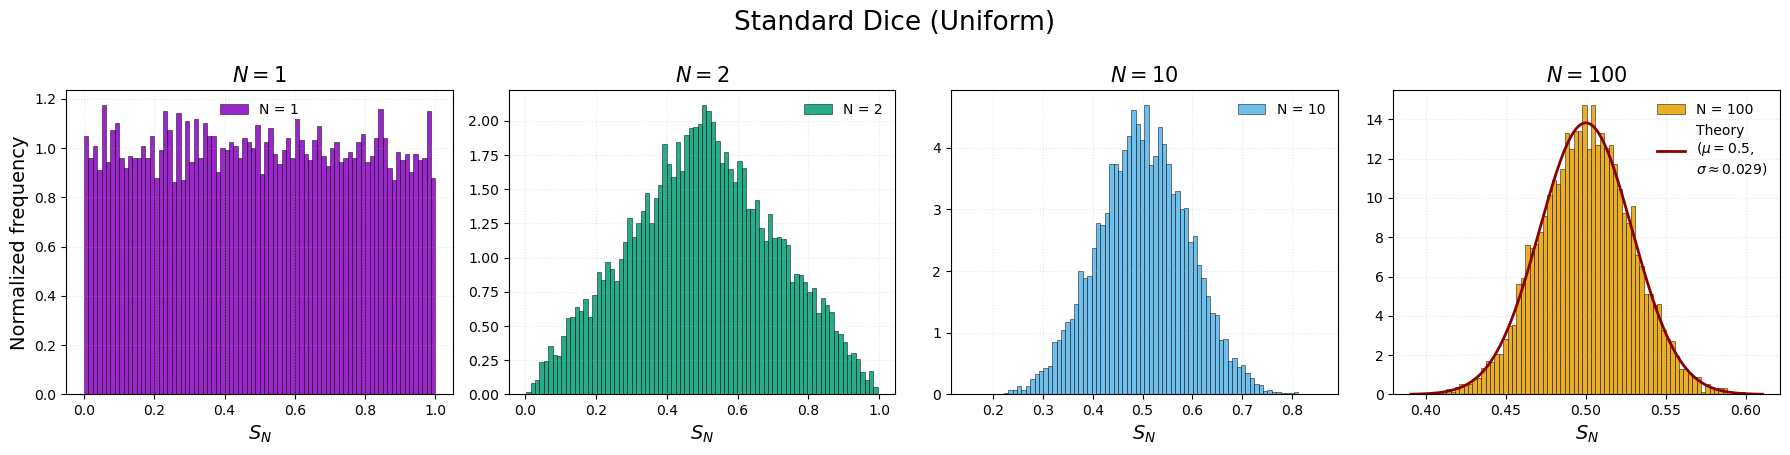

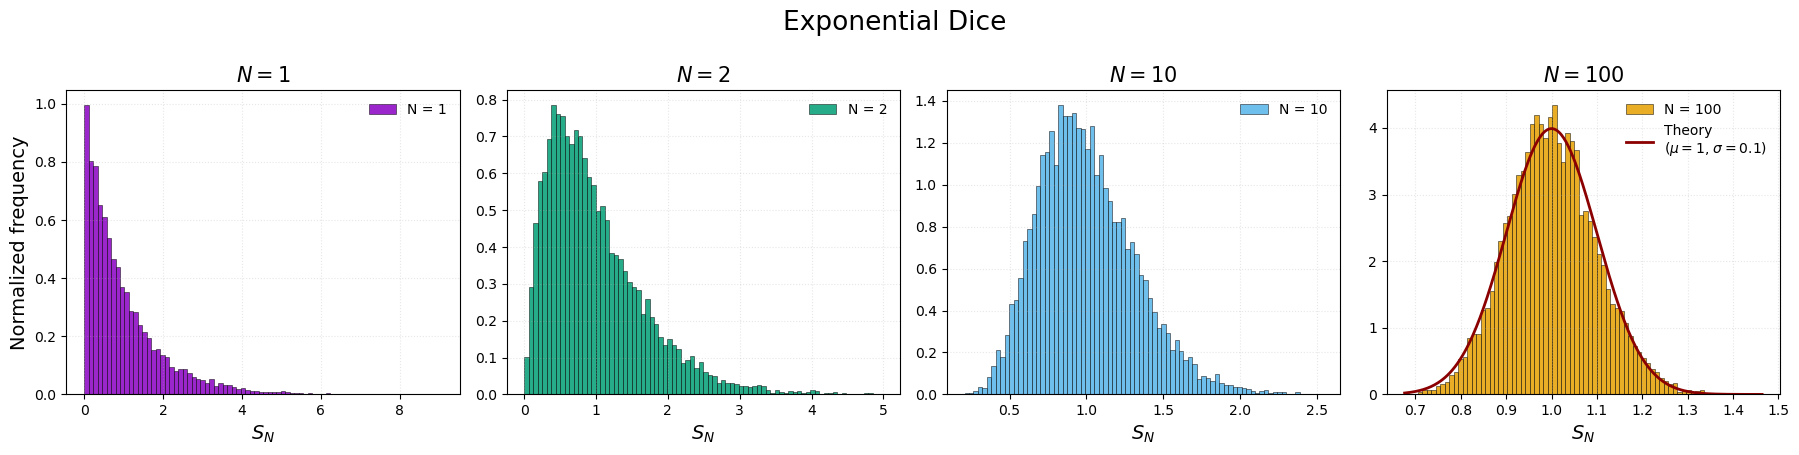

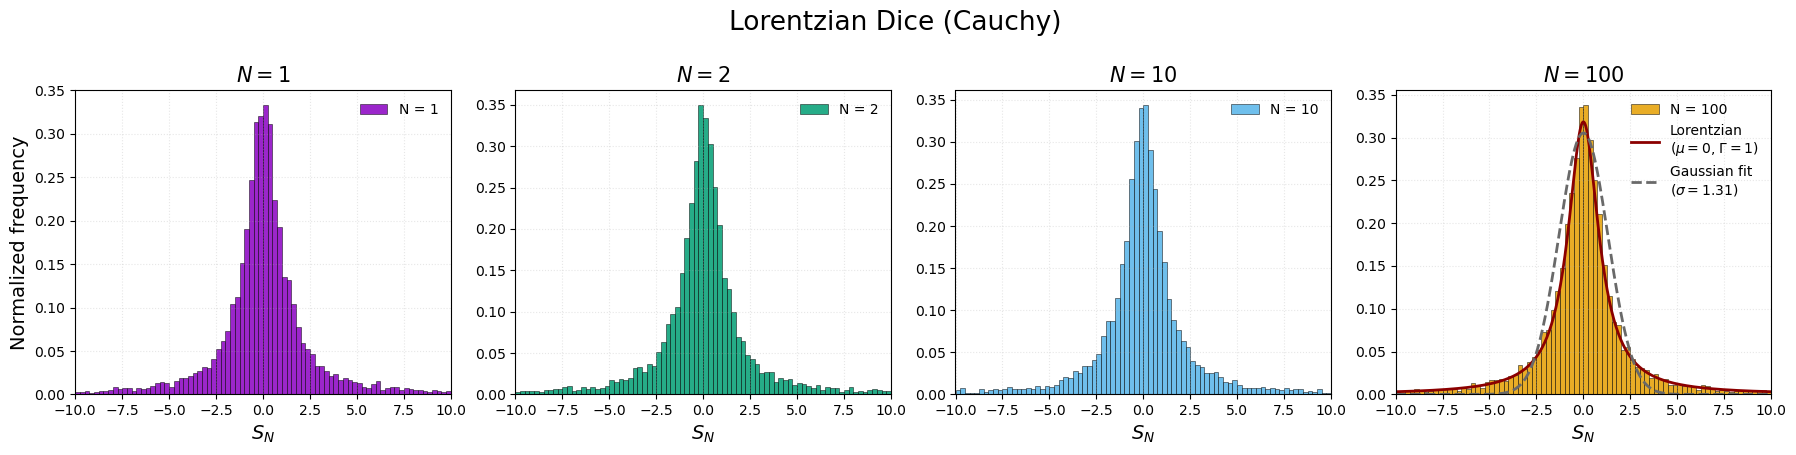

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def gaussian(x, mu, sigma):
    return (1.0 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)

configs = [
    {
        "file": "1.2/OUTPUT/uniform.dat",
        "title": "Standard Dice (Uniform)",
        "theory_type": "gauss",
        "mu": 0.5,
        "sigma": np.sqrt(1.0 / 12.0) / np.sqrt(100),  # 1 / sqrt(1200) ≈ 0.02887
        "label": r"Theory" + "\n" + r"($\mu=0.5$," + "\n" + r"$\sigma\approx0.029$)",
        "range": None,
        "xlim": None,
    },
    {
        "file": "1.2/OUTPUT/exponential.dat",
        "title": "Exponential Dice",
        "theory_type": "gauss",
        "mu": 1.0,
        "sigma": 1.0 / np.sqrt(100),  # 0.1
        "label": r"Theory" + "\n" + r"($\mu=1$, $\sigma=0.1$)",
        "range": None,
        "xlim": None,
    },
    {
        "file": "1.2/OUTPUT/cauchy.dat",
        "title": "Lorentzian Dice (Cauchy)",
        "theory_type": "cauchy",
        "x0": 0.0,
        "gamma": 1.0,
        "label": r"Lorentzian" + "\n" + r"($\mu=0$, $\Gamma=1$)",
        "range": (-10, 10),
        "xlim": (-10, 10),
    },
]

N_vals = [1, 2, 10, 100]
colors = ['#8A00C2', '#009E73', '#56B4E9', '#E69F00']

for cfg in configs:
    s1, s2, s10, s100 = np.loadtxt(cfg["file"], unpack=True)
    data_list = [s1, s2, s10, s100]

    fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(18, 4.5), sharey=False)

    for ax, data, N, color in zip(axs, data_list, N_vals, colors):
        ax.hist(
            data,
            bins=80,
            range=cfg["range"],
            density=True,
            histtype='bar',
            color=color,
            edgecolor='black',
            linewidth=0.4,
            alpha=0.85,
            label=f'N = {N}'
        )
        if cfg["xlim"]:
            ax.set_xlim(cfg["xlim"])
            
        ax.set_title(f'$N = {N}$', fontsize=15, fontweight='bold')
        ax.set_xlabel(r'$S_N$', fontsize=14)
        ax.grid(True, alpha=0.3, linestyle=':')

    # Calcolo curve sul quarto asse (N = 100)
    if cfg["theory_type"] == "gauss":
        mu, sigma = cfg["mu"], cfg["sigma"]
        x_theo = np.linspace(s100.min(), s100.max(), 300)
        y_theo = gaussian(x_theo, mu, sigma)
        axs[3].plot(x_theo, y_theo, color='darkred', linewidth=2, label=cfg["label"])

    elif cfg["theory_type"] == "cauchy":
        x0, gamma = cfg["x0"], cfg["gamma"]
        x_theo = np.linspace(cfg["xlim"][0], cfg["xlim"][1], 500)
        y_theo = (1.0 / np.pi) * (gamma / ((x_theo - x0)**2 + gamma**2))
        axs[3].plot(x_theo, y_theo, color='darkred', linewidth=2, label=cfg["label"])

        # Fit gaussiano sui dati compresi nell'intervallo visibile [-10, 10]
        counts, bin_edges = np.histogram(s100, bins=80, range=cfg["range"], density=True)
        bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
        popt, _ = curve_fit(gaussian, bin_centers, counts, p0=[0.0, 1.5])
        
        y_gauss_fit = gaussian(x_theo, *popt)
        axs[3].plot(
            x_theo, 
            y_gauss_fit, 
            color='dimgrey', 
            linestyle='--', 
            linewidth=2, 
            label=rf'Gaussian fit' + '\n' + rf'($\sigma={popt[1]:.2f}$)'
        )

    for ax in axs:
        ax.legend(frameon=False, fontsize=10)

    axs[0].set_ylabel('Normalized frequency', fontsize=14)
    fig.suptitle(cfg["title"], fontsize=19, y=1)

    plt.tight_layout()
    plt.show()

As expected, we can see that both uniform and exponential distribution, satisfy the central limit theorem, as already at $N=100$ the histogram fit well the gaussian distribution. Instead, the Cauchy-Lorentz distribution must be fitted with a lorentzian distribution, since his variance is not finite, hence **it doesn't satify CLT hypothesis**.

## Exercise 1.3

- **Simulate** the Buffon’s experiment (see LSN_Lecture_00, supplementary material):  A needle of length $L$ is thrown at random onto a horizontal plane ruled with straight lines a distance $d$ (must be $d > L$, but do not use $d\gg L$ otherwise $P\ll 1$) apart. The probability $P$ that the needle will intersect one of these lines is: $P = 2L/\pi d$. This could be used to evaluate $\pi$ from throws of the needle: if the needle is thrown down $N_{thr}$ times and is observed to land on a line $N_{hit}$ of those times, we can make an estimate of $\pi$ from
$$\pi = \frac{2L}{Pd} = \lim_{N_{thr} \to \infty}\frac{2LN_{thr}}{N_{hit}d}$$
Make a picture of the estimation of $\pi$ and its uncertainty (Standard Deviation of the mean) with a large number of *throws* $M$ as a function of the number of blocks, $N$ (see below: Computing statistical uncertainties). If possible, do not use $\pi$ to evaluate $\pi$.

### **Solution**

**Monte Carlo Estimation of $\pi$ via Buffon’s Needle**

To estimate the value of $\pi$ without using trigonometric functions or the numerical value of $\pi$, I implemented a Monte Carlo simulation of Buffon's needle experiment.

* **Sampling the needle position:** By exploiting the periodicity of the parallel lines separated by a distance $d$ and the reflection symmetry about the midline, the position of the needle's center was sampled uniformly in the reduced interval $[0, d/2]$, representing the shortest distance to the nearest line.
* **Sampling the orientation:** To determine the angle $\theta$ uniformly without relying on $\pi$, I employed a 2D rejection technique. Points $(x, y)$ were generated inside the unit square $[0, 1) \times [0, 1)$ and accepted only if they fell within the unit quarter-circle ($x^2 + y^2 \le 1$). This rotational invariance guarantees a uniform angular distribution in $[0, \pi/2)$, allowing the geometric evaluation of $\sin\theta = y / \sqrt{x^2 + y^2}$.
* **Hit condition and estimation:** An intersection occurs whenever the projection of half the needle length onto the perpendicular axis equals or exceeds the distance to the nearest line:
  $$y_{\text{center}} \le \frac{L_{\text{buff}}}{2}\sin\theta$$
  where $L_{buff}$ is the needle length. By recording the fraction of intersecting needles over $L$ throws, $\pi$ is directly evaluated through Buffon’s relation:
  $$\pi \approx \frac{2 L_{\text{buff}} L}{d \cdot \text{hits}}$$
  where L is the usual parameter for data blocking method.

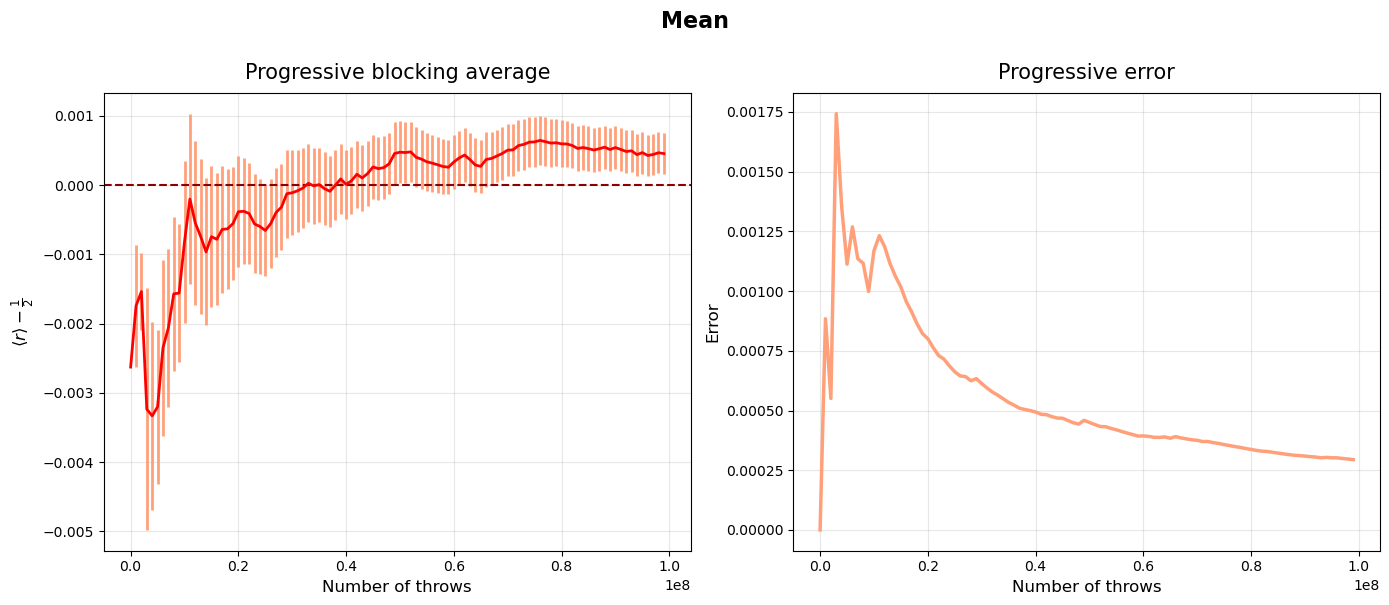

In [10]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), tight_layout=True)
fig.suptitle("Mean", fontsize=16, fontweight='bold', y=1)
axs[0].errorbar(throws_buff, value_buff, yerr=err_buff, fmt='-', color='red', ecolor='lightsalmon', elinewidth=2, linewidth=2)
axs[0].set_title('Progressive blocking average', fontsize=15, pad=10)
axs[0].set_xlabel('Number of throws',  fontsize=12)
axs[0].set_ylabel(r'$\langle r \rangle - \frac{1}{2}$', fontsize=12)
axs[0].grid(True, alpha=0.3)
axs[0].axhline(y=0, color='darkred', linestyle='--', linewidth=1.5)
#axs[0].set_xlim(0, max(throws))

axs[1].plot(throws_buff, err_buff, label='Integral error', color='lightsalmon',  linewidth=2.5)
axs[1].set_title('Progressive error', fontsize=15, pad=10)
axs[1].grid(True, alpha=0.3)
axs[1].set_xlabel('Number of throws',  fontsize=12)
axs[1].set_ylabel('Error',  fontsize=12);
#axs[1].set_xlim(0, max(throws))

The estimated value is fully compatible with the theoretical expectation, falling within $2\sigma$ from the exact value of $\pi$.


**Plot parameters**:
* $M = 10^8$ 
* $N = 10^2$
* $L = 10^6$